In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import sys






raiz = Path.cwd().resolve()
while not (raiz / "baseDeDados" / "economatica-3.xlsx").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("Base Economatica não encontrada")
    raiz = raiz.parent
    arquivo = raiz / "baseDeDados" / "economatica-3.xlsx"

print("Python:", sys.executable)
print("Repositório:", raiz)
print("Planilha encontrada:", arquivo.exists())

Python: c:\Python314\python.exe
Repositório: C:\Users\julio\PBL FGV\FGV QUANT\treinee\TraineeFGVquant
Planilha encontrada: True


In [3]:
pasta_garch = raiz / "notebooks e resultados" / "momentum com garch"
sys.path.insert(0, str(pasta_garch))


from initial_test import preparar_dados

precos, retornos, momentos, datas = preparar_dados(
    path=arquivo,
    inicio_hist="2015-01-01",
    inicio_bt="2017-01-01",
    fim="2021-12-31"
)

print("\nNúmero de ações:", precos.shape[1])
print("Período:", precos.index.min(), "até", precos.index.max())

display(precos.iloc[:5, :5])

[dados] 30 ativos | 2015-01-02 a 2021-12-30 | 60 datas de sinal

Número de ações: 30
Período: 2015-01-02 00:00:00 até 2021-12-30 00:00:00


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5
Data,,,,,
2015-01-02,10.017999,1.992412,6.786634,5.277083,11.473244
2015-01-05,9.798992,1.933689,6.800631,5.167580,10.781290
2015-01-06,10.080572,1.952564,7.024349,5.239805,10.550639
2015-01-07,10.330865,2.036455,7.303501,5.470459,10.544049
2015-01-08,10.372405,2.015482,7.341118,5.489098,10.570409


In [4]:
from funcoes_momentum import backtest

# Verificar quais ações possuem 21 retornos consecutivos válidos
elegiveis = (
    retornos.notna()
    .rolling(window=21, min_periods=21)
    .sum()
    .eq(21)
)

# Considerar apenas as datas mensais de rebalanceamento
pesos_eq30 = elegiveis.loc[datas].astype(float)

# Quantidade de ações elegíveis em cada mês
n_elegiveis = pesos_eq30.sum(axis=1)

if (n_elegiveis == 0).any():
    raise ValueError("Há meses sem ações elegíveis.")

# Distribuir igualmente os pesos entre as elegíveis
pesos_eq30 = pesos_eq30.div(n_elegiveis, axis=0)

# Executar o backtest
resultado_eq30 = backtest(
    pesos_eq30,
    retornos,
    inicio="2017-01-01",
    fim="2021-12-31"
)

print("Quantidade de ações elegíveis por mês:")
display(n_elegiveis.to_frame("Nº de ações").head(12))

print("Resultado do backtest:")
display(resultado_eq30.head())

Quantidade de ações elegíveis por mês:


,Nº de ações
Data,
2017-01-31,29.0
2017-02-24,29.0
2017-03-31,29.0
2017-04-28,29.0
2017-05-31,29.0
2017-06-30,29.0
2017-07-31,29.0
2017-08-31,29.0
2017-09-29,29.0


Resultado do backtest:


,Retorno,Turnover
Data,,
2017-01-02,0.0,0.0
2017-01-03,0.0,0.0
2017-01-04,0.0,0.0
2017-01-05,0.0,0.0
2017-01-06,0.0,0.0


In [5]:
from funcoes_momentum import calcular_metricas

periodos = {
    "Treinamento (2017–2020)": ("2017-01-01", "2020-12-31"),
    "Validação (2021)": ("2021-01-01", "2021-12-31")
}

metricas_eq30 = {}

for nome, (inicio,fim) in periodos.items():
    resultado_periodo = resultado_eq30.loc[inicio:fim]
    metricas_eq30[nome] = calcular_metricas(resultado_periodo, custo=0.001)
tabela_eq30 = pd.DataFrame(metricas_eq30).T
display(tabela_eq30.round(3))

,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
Treinamento (2017–2020),31.130,27.973,1.112,-47.108,1.060
Validação (2021),1.249,21.167,0.164,-18.479,0.851


In [6]:
from initial_test import load_data


# 1. Localizar a planilha original
arquivo_indices = Path(r"C:\Users\julio\Downloads\economatica (1).xlsx")

# 2. Ler e tratar os dados da Economatica
indices = load_data(arquivo_indices)

# 3. Padronizar nomes das colunas
indices.columns = indices.columns.astype(str).str.strip().str.upper()

# 4. Selecionar somente os índices desejados
colunas = ["IBOV", "IBXL", "SMLL", "IDIV"]

faltantes = [c for c in colunas if c not in indices.columns]

if faltantes:
    raise ValueError(
        f"Índices não identificados: {faltantes}. "
        f"Colunas encontradas: {indices.columns.tolist()}"
    )

indices = indices[colunas].copy()

# 5. Restringir ao período de análise
indices = indices.loc["2015-01-01":"2021-12-31"]

# 6. Remover datas em que todos os índices estão ausentes
indices = indices.dropna(how="all")

# 7. Verificar valores inválidos
indices = indices.where(indices > 0)

# 8. Organizar a base
indices = indices.sort_index()
indices.index.name = "Data"

# 9. Salvar a base limpa
saida = raiz / "baseDeDados" / "indices_benchmark_limpo.xlsx"
indices.to_excel(saida)

# 10. Conferir resultados
print("Período:", indices.index.min(), "até", indices.index.max())
print("Observações:", len(indices))
print("Índices:", indices.columns.tolist())

print("\nValores ausentes por índice:")
print(indices.isna().sum())

display(indices.head())
display(indices.tail())

print("\nArquivo salvo em:", saida)

Período: 2015-01-02 00:00:00 até 2021-12-30 00:00:00
Observações: 1730
Índices: ['IBOV', 'IBXL', 'SMLL', 'IDIV']

Valores ausentes por índice:
IBOV    0
IBXL    0
SMLL    0
IDIV    0
dtype: int64


,IBOV,IBXL,SMLL,IDIV
Data,,,,
2015-01-02,48512.0,8218.0,1062.0,2697.0
2015-01-05,47516.0,8048.0,1033.0,2652.0
2015-01-06,48000.0,8127.0,1027.0,2674.0
2015-01-07,49462.0,8373.0,1044.0,2758.0
2015-01-08,49943.0,8448.0,1047.0,2761.0


,IBOV,IBXL,SMLL,IDIV
Data,,,,
2021-12-23,104891.32,17551.83,2318.26,6305.58
2021-12-27,105554.40,17652.84,2340.37,6356.67
2021-12-28,104864.17,17488.59,2357.04,6359.12
2021-12-29,104107.24,17393.67,2326.04,6315.97
2021-12-30,104822.44,17503.96,2365.24,6350.44



Arquivo salvo em: C:\Users\julio\PBL FGV\FGV QUANT\treinee\TraineeFGVquant\baseDeDados\indices_benchmark_limpo.xlsx


In [7]:
retornos_indices = indices.pct_change(fill_method=None)
datas_comuns = retornos.loc["2017":"2021"].index
retornos_indices = retornos_indices.reindex(datas_comuns)
print("Retornos ausentes por índice:")
print(retornos_indices.isna().sum())

print("\nPeríodo:")
print(retornos_indices.index.min(), "até", retornos_indices.index.max())

# 4. Visualizar os dados
display(retornos_indices.head(10))

Retornos ausentes por índice:
IBOV    0
IBXL    0
SMLL    0
IDIV    0
dtype: int64

Período:
2017-01-02 00:00:00 até 2021-12-30 00:00:00


,IBOV,IBXL,SMLL,IDIV
Data,,,,
2017-01-02,-0.010610,-0.010630,-0.004496,-0.007385
2017-01-03,0.037340,0.037152,0.031617,0.036268
2017-01-04,-0.003624,-0.004163,0.007881,0.002991
2017-01-05,0.007810,0.007972,0.007819,-0.001789
2017-01-06,-0.006525,-0.006269,-0.009483,-0.004780
2017-01-09,0.000568,0.000388,0.003481,0.000901
2017-01-10,0.006985,0.006986,0.001735,0.005399
2017-01-11,0.005070,0.004817,0.002597,0.000895
2017-01-12,0.024133,0.023300,0.028497,0.025037


In [8]:
from funcoes_momentum import calcular_metricas

faltantes = retornos_indices.isna().sum()

if (faltantes > 0).any():
    raise ValueError(
        f"Existem retornos ausentes:\n{faltantes}")


resultados_benchmarks = {}
for indice in retornos_indices.columns:
    resultados_benchmarks[indice] = pd.DataFrame({"Retorno":retornos_indices[indice], "Turnover": 0.0})
resultados_benchmarks["Equiponderada 30"] = resultado_eq30


tabelas_benchmarcks = {}

for periodo, (inicio,fim) in periodos.items():
    tabela = pd.DataFrame({
        nome: calcular_metricas(
            resultado.loc[inicio:fim],
            custo=0.001
        )
        for nome, resultado in resultados_benchmarks.items()
    }).T

    tabelas_benchmarcks[periodo] = tabela
    display(tabela.round(3))

,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
IBOV,18.974,28.161,0.760,-46.816,0.00
IBXL,18.474,28.677,0.737,-47.675,0.00
SMLL,26.816,28.667,0.976,-51.693,0.00
IDIV,20.655,25.399,0.868,-40.931,0.00
Equiponderada 30,31.130,27.973,1.112,-47.108,1.06


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
IBOV,-12.153,20.987,-0.512,-22.941,0.000
IBXL,-10.742,21.474,-0.422,-23.428,0.000
SMLL,-16.496,25.528,-0.578,-31.305,0.000
IDIV,-6.538,19.059,-0.260,-15.993,0.000
Equiponderada 30,1.249,21.167,0.164,-18.479,0.851


In [12]:
from funcoes_momentum import criar_top_n, criar_pesos, backtest
carteira_top5 = criar_top_n(momentos["12-1"],n=5)

pesos_top5 = criar_pesos(carteira_top5, retornos.columns)
resultado_top5 = backtest(pesos_top5, retornos, inicio = "2017-01-01",fim = "2021-12-31")
resultados_benchmarks["momentum 12-1 Top5"] = resultado_top5

for periodo, (inicio,fim) in periodos.items():
    tabela = pd.DataFrame({
        nome: calcular_metricas(
            resultado.loc[inicio:fim],
            custo=0.001)
            for nome, resultado in resultados_benchmarks.items()}).T
print(f"\n{periodo}")
display(tabela.round(3))


Validação (2021)


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
IBOV,-12.153,20.987,-0.512,-22.941,0.000
IBXL,-10.742,21.474,-0.422,-23.428,0.000
SMLL,-16.496,25.528,-0.578,-31.305,0.000
IDIV,-6.538,19.059,-0.260,-15.993,0.000
Equiponderada 30,1.249,21.167,0.164,-18.479,0.851
momentum 12-1 Top5,24.656,33.602,0.823,-23.028,5.746


In [15]:
from initial_test import prever_vol, criar_pesos_vol

modelo = ("gjr", 756)

sigmas, fallbacks = prever_vol(retornos, datas, specs=[modelo], workers=1, cache_path=str(raiz / "cache_vol_mensal.pkl"))
pesos_gjr = criar_pesos_vol(carteira_top5, sigmas[modelo], retornos.columns)
resultado_gjr = backtest(pesos_gjr, retornos,  inicio="2017-01-01", fim="2021-12-31")
resultados_benchmarks["Momentum 12-1 Top 5 GJR"] = resultado_gjr

print("Fallbacks para EWMA:", fallbacks[modelo])
display(pesos_gjr.loc[:, (pesos_gjr != 0).any()].head())


[vol] cache: 1/1 especificações prontas
Fallbacks para EWMA: 0


,B3SA3,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,GGBR4,GOAU4,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.234100,0.197712,...,0.279491,0.000000,0.0,0.000000,0.0,0.0,0.0,0.179511,0.000000,0.0
2017-02-24,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.218121,0.193126,...,0.285598,0.000000,0.0,0.000000,0.0,0.0,0.0,0.188150,0.000000,0.0
2017-03-31,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.205258,...,0.000000,0.000000,0.0,0.237848,0.0,0.0,0.0,0.189646,0.215847,0.0
2017-04-28,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.221693,...,0.000000,0.164409,0.0,0.250472,0.0,0.0,0.0,0.209038,0.000000,0.0
2017-05-31,0.0,0.278667,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.192391,...,0.000000,0.177218,0.0,0.000000,0.0,0.0,0.0,0.201595,0.000000,0.0


In [18]:
tabelas_finais = {}

for periodo, (inicio, fim) in periodos.items():

    tabela = pd.DataFrame({
        nome: calcular_metricas(
            resultado.loc[inicio:fim],
            custo=0.001
        )
        for nome, resultado in resultados_benchmarks.items()
    }).T

    tabela = tabela.sort_values("Sharpe", ascending=False)

    tabelas_finais[periodo] = tabela

    print(f"\n{periodo}")
    display(tabela.round(3))


Treinamento (2017–2020)


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
momentum 12-1 Top5,48.951,36.387,1.283,-51.292,6.034
Momentum 12-1 Top 5 GJR,38.234,33.885,1.130,-45.915,7.101
Equiponderada 30,31.130,27.973,1.112,-47.108,1.060
SMLL,26.816,28.667,0.976,-51.693,0.000
IDIV,20.655,25.399,0.868,-40.931,0.000
IBOV,18.974,28.161,0.760,-46.816,0.000
IBXL,18.474,28.677,0.737,-47.675,0.000



Validação (2021)


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
momentum 12-1 Top5,24.656,33.602,0.823,-23.028,5.746
Momentum 12-1 Top 5 GJR,22.197,33.244,0.769,-23.756,6.567
Equiponderada 30,1.249,21.167,0.164,-18.479,0.851
IDIV,-6.538,19.059,-0.260,-15.993,0.000
IBXL,-10.742,21.474,-0.422,-23.428,0.000
IBOV,-12.153,20.987,-0.512,-22.941,0.000
SMLL,-16.496,25.528,-0.578,-31.305,0.000


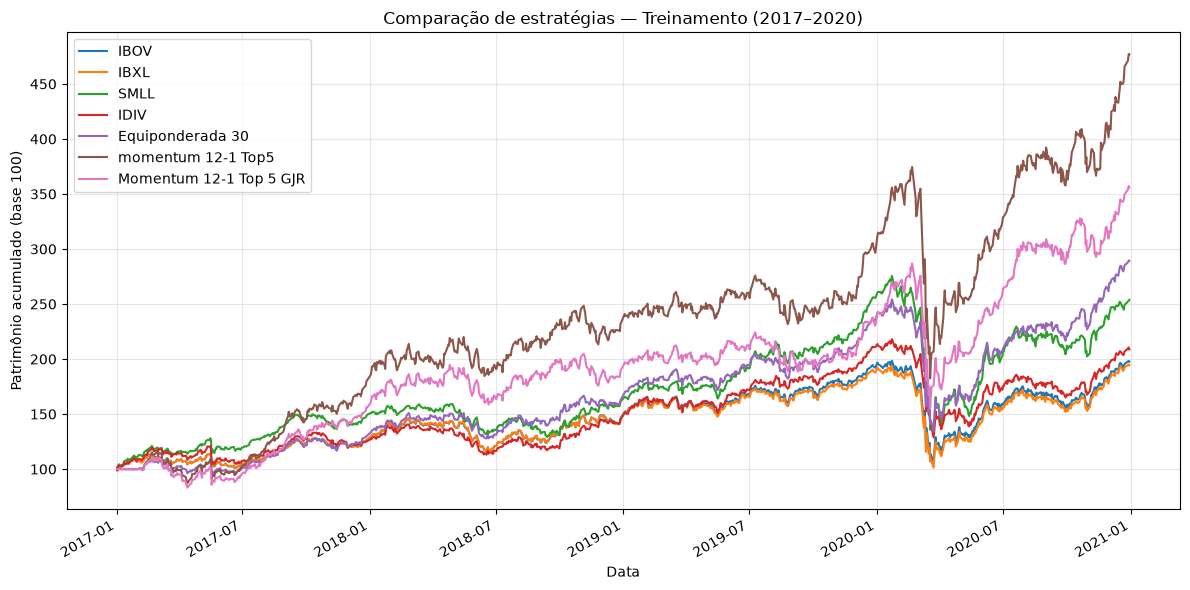

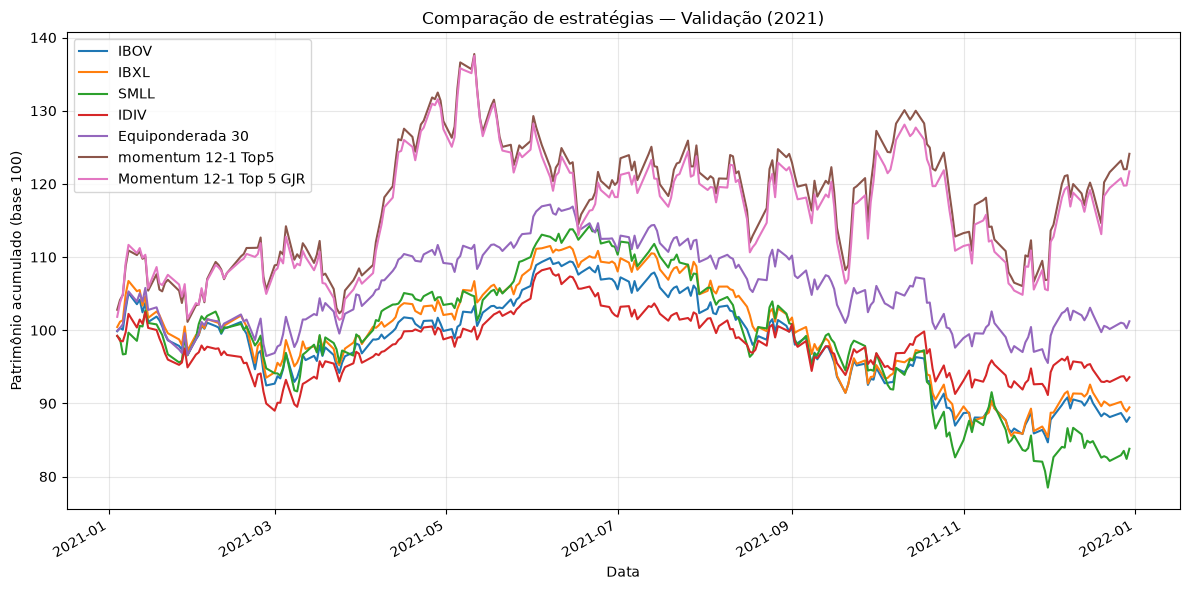

In [19]:
import matplotlib.pyplot as plt
from funcoes_momentum import aplicar_custos

for periodo, (inicio, fim) in periodos.items():

    patrimonio = pd.DataFrame({
        nome: (1 + aplicar_custos(
            resultado.loc[inicio:fim],
            custo=0.001
        )).cumprod() * 100

        for nome, resultado in resultados_benchmarks.items()
    })

    ax = patrimonio.plot(
        figsize=(12, 6),
        title=f"Comparação de estratégias — {periodo}",
        linewidth=1.5
    )

    ax.set_ylabel("Patrimônio acumulado (base 100)")
    ax.set_xlabel("Data")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [20]:
import numpy as np
import pandas as pd
from funcoes_momentum import aplicar_custos

estrategias = [
    "momentum 12-1 Top5",
    "Momentum 12-1 Top 5 GJR",
    "Equiponderada 30"
]

linhas = []

for periodo, (inicio, fim) in periodos.items():

    ibov = resultados_benchmarks["IBOV"].loc[inicio:fim, "Retorno"]

    for nome in estrategias:

        carteira = resultados_benchmarks[nome].loc[inicio:fim]

        # Retorno líquido da estratégia
        rp = aplicar_custos(carteira, custo=0.001)

        # Alinhar as datas
        dados = pd.concat(
            [rp.rename("Carteira"), ibov.rename("IBOV")],
            axis=1
        ).dropna()

        # Beta em relação ao Ibovespa
        beta = dados["Carteira"].cov(dados["IBOV"]) / dados["IBOV"].var()

        # Correlação
        correlacao = dados["Carteira"].corr(dados["IBOV"])

        # Retorno ativo diário
        ativo = dados["Carteira"] - dados["IBOV"]

        # Information Ratio anualizado
        ir = ativo.mean() / ativo.std() * np.sqrt(252)

        linhas.append({
            "Período": periodo,
            "Estratégia": nome,
            "Beta IBOV": beta,
            "Correlação": correlacao,
            "Information Ratio": ir
        })

tabela_risco = pd.DataFrame(linhas)

display(tabela_risco.round(3))

,Período,Estratégia,Beta IBOV,Correlação,Information Ratio
0,Treinamento (2017–2020),momentum 12-1 Top5,1.040,0.805,1.170
1,Treinamento (2017–2020),Momentum 12-1 Top 5 GJR,0.958,0.796,0.822
2,Treinamento (2017–2020),Equiponderada 30,0.961,0.967,1.348
3,Validação (2021),momentum 12-1 Top5,1.085,0.678,1.550
4,Validação (2021),Momentum 12-1 Top 5 GJR,1.083,0.683,1.492
5,Validação (2021),Equiponderada 30,0.975,0.967,2.620


In [21]:
linhas = []

for periodo, (inicio, fim) in periodos.items():

    ibov = resultados_benchmarks["IBOV"].loc[inicio:fim, "Retorno"]

    for nome in estrategias:

        carteira = resultados_benchmarks[nome].loc[inicio:fim]

        rp = aplicar_custos(carteira, custo=0.001)

        dados = pd.concat(
            [rp.rename("Carteira"), ibov.rename("IBOV")],
            axis=1
        ).dropna()

        ativo = dados["Carteira"] - dados["IBOV"]

        retorno_ativo = ativo.mean() * 252 * 100
        tracking_error = ativo.std(ddof=1) * np.sqrt(252) * 100

        linhas.append({
            "Período": periodo,
            "Estratégia": nome,
            "Retorno ativo (%)": retorno_ativo,
            "Tracking Error (%)": tracking_error,
            "Information Ratio": (retorno_ativo / tracking_error)
        })

tabela_ativo = pd.DataFrame(linhas)

display(tabela_ativo.round(3))

,Período,Estratégia,Retorno ativo (%),Tracking Error (%),Information Ratio
0,Treinamento (2017–2020),momentum 12-1 Top5,25.273,21.605,1.170
1,Treinamento (2017–2020),Momentum 12-1 Top 5 GJR,16.879,20.529,0.822
2,Treinamento (2017–2020),Equiponderada 30,9.692,7.189,1.348
3,Validação (2021),momentum 12-1 Top5,38.418,24.779,1.550
4,Validação (2021),Momentum 12-1 Top 5 GJR,36.306,24.330,1.492
5,Validação (2021),Equiponderada 30,14.228,5.430,2.620


In [22]:
from initial_test import baixar_cdi
import pandas as pd

# Caminho do cache dentro do repositório
arquivo_cdi = raiz / "baseDeDados" / "cdi_sgs12.csv"

# Recuperar o histórico já salvo no GitHub, caso não exista localmente
if not arquivo_cdi.exists():

    url = (
        "https://raw.githubusercontent.com/"
        "julioturolla/TraineeFGVquant/"
        "7c7ef69451a732f25ecf3aaf6d10c151c2bac50d/"
        "cdi_sgs12.csv"
    )

    historico_cdi = pd.read_csv(url)
    historico_cdi.to_csv(arquivo_cdi, index=False)

# Utilizar a função original do projeto
cdi_diario = baixar_cdi(
    inicio="2017-01-01",
    fim="2021-12-31",
    cache=str(arquivo_cdi)
)

if cdi_diario is None:
    raise ValueError("Não foi possível carregar o CDI.")

# Conferir os dados
print("Primeira data:", cdi_diario.index.min())
print("Última data:", cdi_diario.index.max())

display(cdi_diario.head())

Primeira data: 2016-11-17 00:00:00
Última data: 2021-12-31 00:00:00


data
2016-11-17    0.000516
2016-11-18    0.000516
2016-11-21    0.000516
2016-11-22    0.000516
2016-11-23    0.000516
Name: cdi, dtype: float64

In [24]:
tabelas_finais_cdi = {}

for periodo, (inicio, fim) in periodos.items():

    tabela = pd.DataFrame({
        nome: calcular_metricas(
            resultado.loc[inicio:fim],
            custo=0.001,
            cdi=cdi_diario
        )
        for nome, resultado in resultados_benchmarks.items()
    }).T

    # Ordenar pelo Sharpe com CDI
    tabela = tabela.sort_values("Sharpe", ascending=False)

    # Guardar os resultados
    tabelas_finais_cdi[periodo] = tabela

    print(f"\n{periodo} — Sharpe com CDI")
    display(tabela.round(3))


Treinamento (2017–2020) — Sharpe com CDI


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
momentum 12-1 Top5,48.951,36.387,1.115,-51.292,6.034
Momentum 12-1 Top 5 GJR,38.234,33.885,0.950,-45.915,7.101
Equiponderada 30,31.130,27.973,0.894,-47.108,1.060
SMLL,26.816,28.667,0.764,-51.693,0.000
IDIV,20.655,25.399,0.629,-40.931,0.000
IBOV,18.974,28.161,0.544,-46.816,0.000
IBXL,18.474,28.677,0.525,-47.675,0.000



Validação (2021) — Sharpe com CDI


,Retorno anual (%),Volatilidade (%),Sharpe,Max Drawdown (%),Turnover anual
momentum 12-1 Top5,24.656,33.602,0.695,-23.028,5.746
Momentum 12-1 Top 5 GJR,22.197,33.244,0.639,-23.756,6.567
Equiponderada 30,1.249,21.167,-0.040,-18.479,0.851
IDIV,-6.538,19.059,-0.486,-15.993,0.000
IBXL,-10.742,21.474,-0.623,-23.428,0.000
IBOV,-12.153,20.987,-0.718,-22.941,0.000
SMLL,-16.496,25.528,-0.747,-31.305,0.000


In [25]:
# Alinhar o CDI às datas do backtest
cdi_alinhado = cdi_diario.reindex(
    retornos.loc["2017":"2021"].index,
    method="ffill"
)

# Verificar valores ausentes
if cdi_alinhado.isna().any():
    raise ValueError("Existem datas sem CDI disponível.")

# Criar benchmark CDI
resultado_cdi = pd.DataFrame({
    "Retorno": cdi_alinhado,
    "Turnover": 0.0
})

# Adicionar ao conjunto de benchmarks
resultados_benchmarks["CDI"] = resultado_cdi

# Conferir
display(resultado_cdi.head())

,Retorno,Turnover
Data,,
2017-01-02,0.000507,0.0
2017-01-03,0.000507,0.0
2017-01-04,0.000507,0.0
2017-01-05,0.000507,0.0
2017-01-06,0.000507,0.0


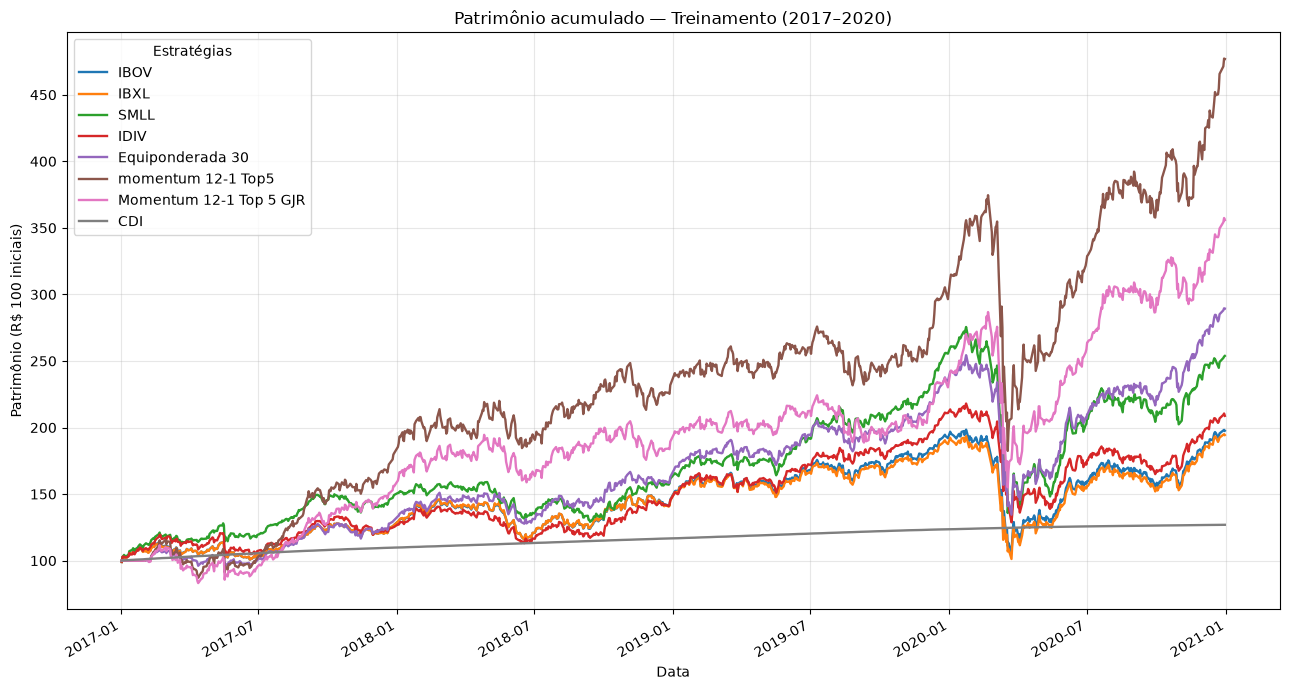

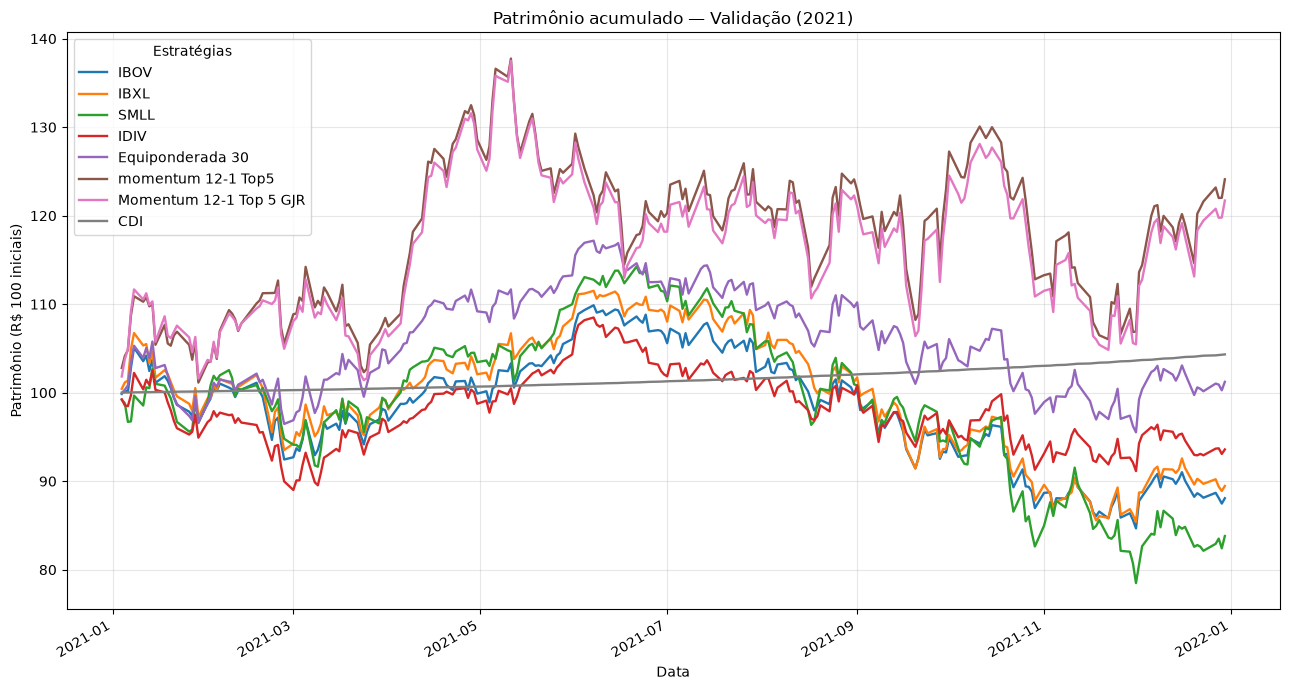

In [26]:
import matplotlib.pyplot as plt
from funcoes_momentum import aplicar_custos

for periodo, (inicio, fim) in periodos.items():

    patrimonio = pd.DataFrame({
        nome: (
            1 + aplicar_custos(
                resultado.loc[inicio:fim],
                custo=0.001
            )
        ).cumprod() * 100

        for nome, resultado in resultados_benchmarks.items()
    })

    ax = patrimonio.plot(
        figsize=(13, 7),
        linewidth=1.7,
        title=f"Patrimônio acumulado — {periodo}"
    )

    ax.set_ylabel("Patrimônio (R$ 100 iniciais)")
    ax.set_xlabel("Data")
    ax.grid(alpha=0.3)
    ax.legend(title="Estratégias")

    plt.tight_layout()
    plt.show()